# Advertising Sales Prediction using Multiple Linear Regression


### Problem Statement
A consumer goods company spends money on TV, Radio and Newspaper advertising. The objective is to understand how these advertising channels affect Sales and predict Sales for a new advertising budget.


## 1. Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 2. Load the Dataset


In [2]:
df = pd.read_csv("Advertising.csv")

print(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9
Shape: (200, 4)
Columns: ['TV', 'Radio', 'Newspaper', 'Sales']


## 3. Select Features and Target
TV, Radio and Newspaper are used as input features, while Sales is the target variable.


In [3]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print("Features:")
print(X.head())
print("\nTarget:")
print(y.head())


Features:
      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4

Target:
0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64


## 4. Split the Data into Training and Testing Sets


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (160, 3)
Testing data: (40, 3)


## 5. Build the Multiple Linear Regression Model
The model learns the relationship:

**Sales = β₀ + β₁(TV) + β₂(Radio) + β₃(Newspaper)**


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully")


Model trained successfully


## 6. Regression Coefficients


In [6]:
print("Intercept:", model.intercept_)
print("TV coefficient:", model.coef_[0])
print("Radio coefficient:", model.coef_[1])
print("Newspaper coefficient:", model.coef_[2])


Intercept: 4.714126402214127
TV coefficient: 0.05450927083721978
Radio coefficient: 0.10094536239295579
Newspaper coefficient: 0.0043366468220340446


## 7. Predict Sales for Test Data


In [7]:
y_pred = model.predict(X_test)

print("Predicted Sales:")
print(y_pred)


Predicted Sales:
[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475  8.92396497  8.4817344
 18.2075123   8.06750728 12.64550975 14.93162809  8.12814594 17.89876565
 11.00880637 20.47832788 20.80631846 12.59883297 10.9051829  22.38854775
  9.41796094  7.92506736 20.83908497 13.81520938 10.77080925  7.92682509
 15.95947357 10.63490851 20.80292008 10.43434164 21.5784752  21.18364487
 12.12821771 22.80953262 12.60992766  6.46441252]


## 8. Evaluate the Model


In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 1.2748262109549338
MSE: 2.9077569102710896
RMSE: 1.7052146229349223
R2 Score: 0.9059011844150826


## 9. Predict Sales for Given Advertising Budget
Given:
- TV = 150
- Radio = 20
- Newspaper = 30


In [9]:
new_data = [[150, 20, 30]]

predicted_sales = model.predict(new_data)

print("Predicted Sales:", predicted_sales[0])


Predicted Sales: 15.039523680317231


C:\Users\srikr\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## 10. Actual vs Predicted Sales


## 10. Actual vs Predicted Sales

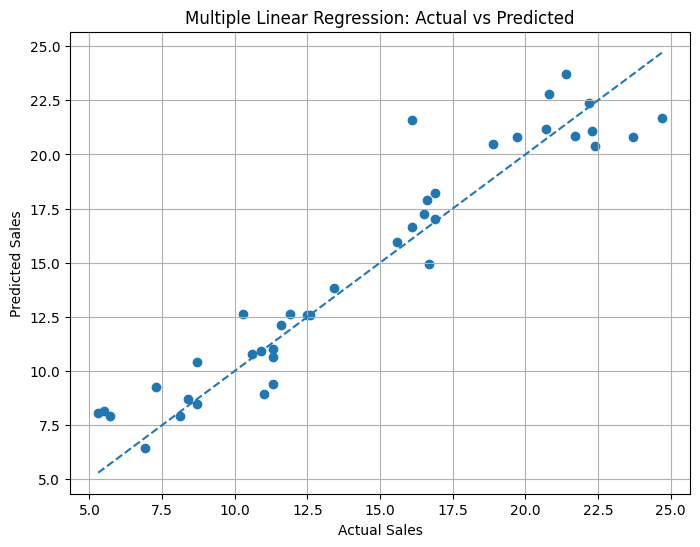

In [13]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.grid(True)

plt.show()

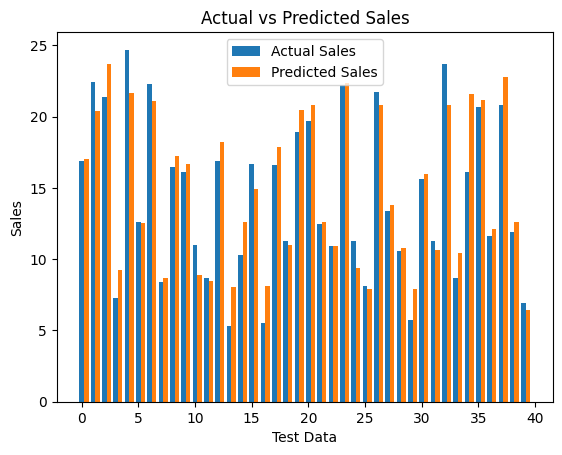

In [11]:
plt.bar(range(len(y_test)), y_test, width=0.4, label="Actual Sales")
plt.bar(np.arange(len(y_pred)) + 0.4, y_pred, width=0.4, label="Predicted Sales")

plt.xlabel("Test Data")
plt.ylabel("Sales")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.show()

## 11. Interpretation
The regression coefficients indicate the estimated impact of each advertising channel on Sales while keeping the other channels constant. The channel with the largest positive coefficient has the strongest estimated impact.

### Business Recommendation
The company should give more attention to the advertising channel with the strongest positive coefficient and use the model to support future budget planning.

### Technical Improvement
K-fold cross-validation can be used to obtain a more reliable estimate of model performance instead of depending on a single train-test split.
